### 06 — Multimodal Benign / Malignant Classification

What this notebook does:

- load the existing training, validation, and test splits
- prepare the clinical-text input
- load the trained U-Net, EfficientNet, and ClinicalBERT components
- generate predicted lesion masks automatically
- combine visual and clinical features using bidirectional cross-attention
- train a binary classifier to predict benign or malignant lesions
- account for class imbalance using a weighted binary classification loss
- save the model with the lowest validation loss
- evaluate the final model on the held-out test set.

The classifier receives a `1536`-dimensional multimodal feature vector made from visual features and clinical features.


### 1. Imports and Setup


In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

PROJECT_ROOT = Path("..").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.unet import UNet
from src.image_encoder import EfficientNetEncoder
from src.clinical_encoder import ClinicalBERTEncoder
from src.fusion import CrossAttentionFusion
from src.classifier import MultimodalClassifier


c:\Users\Akash\Desktop\Python\breast-ultrasound-fyp\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 2. Define Paths and Device

The same project folders and saved checkpoints from the previous notebooks are reused.

CUDA is used when a compatible GPU is available.


In [2]:
DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

IMAGE_DIR = RAW_DIR / "images"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: NVIDIA GeForce GTX 1650


### 3. Load the Dataset Splits

The notebook uses the existing project folders for the raw ultrasound images, processed dataset splits, and trained model checkpoints.


In [3]:
train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
val_df = pd.read_csv(PROCESSED_DIR / "val.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


Train: 176
Validation: 38
Test: 38


### 4. Prepare the Clinical Text

The four clinical variables are converted into the same text structure used in the ClinicalBERT notebook.


In [4]:
def create_clinical_text(row):
    return (
        f"Patient age: {row['Age']} years. "
        f"Tissue composition: {row['Tissue_composition']}. "
        f"Clinical signs: {row['Signs']}. "
        f"Symptoms: {row['Symptoms']}."
    )


for df in (train_df, val_df, test_df):
    df["clinical_text"] = df.apply(create_clinical_text, axis=1)


### 5. Load the ClinicalBERT Tokenizer

`Bio_ClinicalBERT` is used to tokenise the structured clinical text.


In [5]:
MODEL_NAME = "emilyalsentzer/Bio_ClinicalBERT"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


### 6. Create the Multimodal Dataset

Each case contains:
- one grayscale ultrasound image
- ClinicalBERT token IDs
- an attention mask
- token-type IDs when available
- the binary classification target.


In [6]:
class BreastMultimodalDataset(Dataset):
    def __init__(self, dataframe, image_dir, tokenizer, image_size=224, max_length=64):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.tokenizer = tokenizer
        self.image_size = image_size
        self.max_length = max_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(
            self.image_dir / row["Image_filename"]
        ).convert("L")

        image = image.resize(
            (self.image_size, self.image_size),
            Image.BILINEAR
        )

        image = torch.tensor(
            np.array(image, dtype=np.float32) / 255.0,
            dtype=torch.float32
        ).unsqueeze(0)

        encoded = self.tokenizer(
            row["clinical_text"],
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        sample = {
            "image": image,
            "input_ids": encoded["input_ids"].squeeze(0),
            "attention_mask": encoded["attention_mask"].squeeze(0),
            "target": torch.tensor(row["target"], dtype=torch.float32)
        }

        if "token_type_ids" in encoded:
            sample["token_type_ids"] = encoded["token_type_ids"].squeeze(0)

        return sample


### 7. Create the Datasets and Data Loaders

The training loader shuffles the cases, while validation and test loaders keep a fixed order.


In [7]:
train_dataset = BreastMultimodalDataset(train_df, IMAGE_DIR, tokenizer)
val_dataset = BreastMultimodalDataset(val_df, IMAGE_DIR, tokenizer)
test_dataset = BreastMultimodalDataset(test_df, IMAGE_DIR, tokenizer)

BATCH_SIZE = 8

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

batch = next(iter(train_loader))

print("Image:", batch["image"].shape)
print("Input IDs:", batch["input_ids"].shape)
print("Attention mask:", batch["attention_mask"].shape)
print("Target:", batch["target"].shape)


Image: torch.Size([8, 1, 224, 224])
Input IDs: torch.Size([8, 64])
Attention mask: torch.Size([8, 64])
Target: torch.Size([8])


### 8. Load the Trained Model Components

The segmentation model and ClinicalBERT are frozen.

The EfficientNet convolutional backbone is also frozen, while its projection layer remains trainable.


In [8]:
# U-Net
segmentation_model = UNet().to(device)
segmentation_model.load_state_dict(
    torch.load(MODEL_DIR / "best_unet.pth", map_location=device)
)
segmentation_model.eval()

with open(MODEL_DIR / "segmentation_config.json", "r") as f:
    BEST_THRESHOLD = json.load(f)["best_threshold"]

for parameter in segmentation_model.parameters():
    parameter.requires_grad = False

print("Loaded BEST_THRESHOLD:", BEST_THRESHOLD)


# EfficientNet
image_encoder = EfficientNetEncoder(output_dim=768).to(device)

for parameter in image_encoder.features.parameters():
    parameter.requires_grad = False

for parameter in image_encoder.projection.parameters():
    parameter.requires_grad = True


# ClinicalBERT
clinical_encoder = ClinicalBERTEncoder(model_name=MODEL_NAME).to(device)

for parameter in clinical_encoder.parameters():
    parameter.requires_grad = False


# Multimodal fusion and classifier
fusion_model = CrossAttentionFusion(
    embed_dim=768,
    num_heads=8,
    dropout=0.1
).to(device)

classifier = MultimodalClassifier(input_dim=1536).to(device)


Loaded BEST_THRESHOLD: 0.5499999999999999


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 12965.09it/s]
[transformers] BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


### 9. Define Feature Pooling and Image Normalisation

Masked mean pooling ignores padded ClinicalBERT positions

The ImageNet mean and standard deviation are stored once and reused for every batch


In [9]:
IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406],
    device=device
).view(1, 3, 1, 1)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225],
    device=device
).view(1, 3, 1, 1)


def masked_mean_pool(tokens, attention_mask):
    mask = attention_mask.unsqueeze(-1).float()
    summed = (tokens * mask).sum(dim=1)
    counts = mask.sum(dim=1).clamp(min=1e-9)
    return summed / counts


### 10. Define the Multimodal Forward Pipeline

For each batch:

```text
Ultrasound image                        Clinical text
      ↓                                       ↓
U-Net → predicted lesion mask            ClinicalBERT                
      ↓                                       ↓
EfficientNet → visual tokens            clinical tokens
            ↓                                 ↓                     
                Bidirectional cross-attention
                        ↓
                pooled representations
                        ↓
            1536-dimensional feature vector
                        ↓
                binary classifier
```


In [10]:
def forward_multimodal(images, input_ids, attention_mask, token_type_ids=None):
    # 1. Predict lesion masks
    with torch.no_grad():
        segmentation_logits = segmentation_model(images)

    predicted_masks = (
        torch.sigmoid(segmentation_logits) >= BEST_THRESHOLD
    ).float()

    # 2. Prepare images for EfficientNet
    rgb_images = images.repeat(1, 3, 1, 1)
    rgb_images = (rgb_images - IMAGENET_MEAN) / IMAGENET_STD

    # 3. Extract visual and clinical tokens
    visual_tokens = image_encoder(rgb_images, predicted_masks)

    with torch.no_grad():
        clinical_tokens = clinical_encoder(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )

    # 4. Fuse both modalities
    visual_fused, clinical_fused = fusion_model(
        visual_tokens,
        clinical_tokens,
        clinical_padding_mask=(attention_mask == 0)
    )

    # 5. Pool and classify
    visual_vector = visual_fused.mean(dim=1)
    clinical_vector = masked_mean_pool(clinical_fused, attention_mask)

    multimodal_features = torch.cat(
        [visual_vector, clinical_vector],
        dim=1
    )

    return classifier(multimodal_features)


### 11. Helper for Moving a Batch to the Device


In [11]:
def prepare_batch(batch):
    token_type_ids = batch.get("token_type_ids")

    return (
        batch["image"].to(device),
        batch["input_ids"].to(device),
        batch["attention_mask"].to(device),
        token_type_ids.to(device) if token_type_ids is not None else None,
        batch["target"].to(device)
    )


### 12. Test the Forward Pipeline

A training batch is passed through the complete pipeline.


In [12]:
batch = next(iter(train_loader))
images, input_ids, attention_mask, token_type_ids, targets = prepare_batch(batch)

logits = forward_multimodal(
    images,
    input_ids,
    attention_mask,
    token_type_ids
)

print("Logits:", logits.shape)


Logits: torch.Size([8])


### 13. Handle Class Imbalance

The training set contains more benign than malignant cases.

`pos_weight` gives malignant cases additional weight in `BCEWithLogitsLoss`.


In [13]:
num_benign = (train_df["target"] == 0).sum()
num_malignant = (train_df["target"] == 1).sum()

pos_weight = torch.tensor(
    [num_benign / num_malignant],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

print("Benign:", num_benign)
print("Malignant:", num_malignant)
print("Positive weight:", pos_weight.item())


Benign: 108
Malignant: 68
Positive weight: 1.5882352590560913


### 14. Configure the Optimiser

Only the trainable parts of the multimodal model are updated:

- EfficientNet projection layer
- cross-attention fusion model
- classification head.


In [14]:
trainable_parameters = (
    list(image_encoder.projection.parameters())
    + list(fusion_model.parameters())
    + list(classifier.parameters())
)

optimizer = torch.optim.AdamW(
    trainable_parameters,
    lr=1e-4,
    weight_decay=1e-4
)


### 15. Train the Multimodal Classifier

The model is trained for 15 epochs.

The checkpoint with the lowest validation loss is saved as `best_multimodal_classifier.pth`.


In [15]:
EPOCHS = 15

train_losses = []
val_losses = []
val_accuracies = []

best_val_loss = float("inf")
best_val_accuracy = 0.0

for epoch in range(EPOCHS):
    # -------------------------
    # Training
    # -------------------------
    image_encoder.train()
    fusion_model.train()
    classifier.train()

    segmentation_model.eval()
    clinical_encoder.eval()

    running_train_loss = 0.0

    for batch in train_loader:
        images, input_ids, attention_mask, token_type_ids, targets = prepare_batch(batch)

        optimizer.zero_grad()

        logits = forward_multimodal(
            images,
            input_ids,
            attention_mask,
            token_type_ids
        )

        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)

    # -------------------------
    # Validation
    # -------------------------
    image_encoder.eval()
    fusion_model.eval()
    classifier.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch in val_loader:
            images, input_ids, attention_mask, token_type_ids, targets = prepare_batch(batch)

            logits = forward_multimodal(
                images,
                input_ids,
                attention_mask,
                token_type_ids
            )

            loss = criterion(logits, targets)
            running_val_loss += loss.item()

            predictions = (torch.sigmoid(logits) >= 0.5).float()
            correct += (predictions == targets).sum().item()
            total += targets.size(0)

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = correct / total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            {
                "image_encoder": image_encoder.state_dict(),
                "fusion_model": fusion_model.state_dict(),
                "classifier": classifier.state_dict()
            },
            MODEL_DIR / "best_multimodal_classifier.pth"
        )

        print("Best model saved.")


Epoch 01/15 | Train Loss: 0.8342 | Val Loss: 0.8273 | Val Accuracy: 0.7105
Best model saved.
Epoch 02/15 | Train Loss: 0.7953 | Val Loss: 0.8059 | Val Accuracy: 0.4737
Best model saved.
Epoch 03/15 | Train Loss: 0.7122 | Val Loss: 0.6942 | Val Accuracy: 0.7368
Best model saved.
Epoch 04/15 | Train Loss: 0.6074 | Val Loss: 0.6117 | Val Accuracy: 0.8421
Best model saved.
Epoch 05/15 | Train Loss: 0.4246 | Val Loss: 0.7666 | Val Accuracy: 0.7632
Epoch 06/15 | Train Loss: 0.4214 | Val Loss: 0.7558 | Val Accuracy: 0.7895
Epoch 07/15 | Train Loss: 0.3877 | Val Loss: 0.6804 | Val Accuracy: 0.8421
Epoch 08/15 | Train Loss: 0.3069 | Val Loss: 0.8632 | Val Accuracy: 0.7105
Epoch 09/15 | Train Loss: 0.2992 | Val Loss: 1.1468 | Val Accuracy: 0.7105
Epoch 10/15 | Train Loss: 0.3129 | Val Loss: 0.9697 | Val Accuracy: 0.7105
Epoch 11/15 | Train Loss: 0.2670 | Val Loss: 1.0227 | Val Accuracy: 0.6842
Epoch 12/15 | Train Loss: 0.1572 | Val Loss: 1.0914 | Val Accuracy: 0.7105
Epoch 13/15 | Train Loss: 0.

### 16. Review the Training Curves

The loss curves help show convergence and possible overfitting.


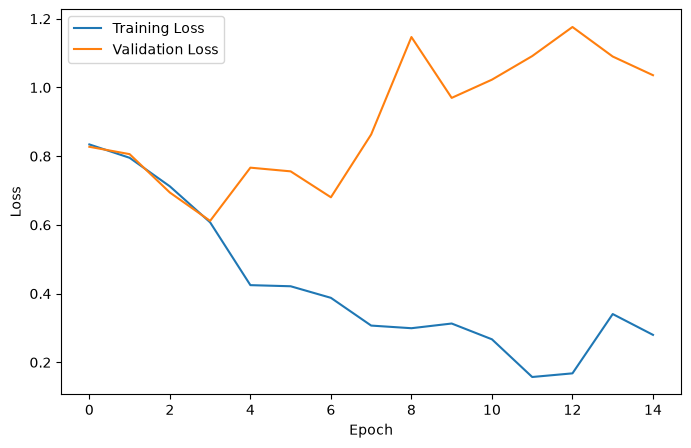

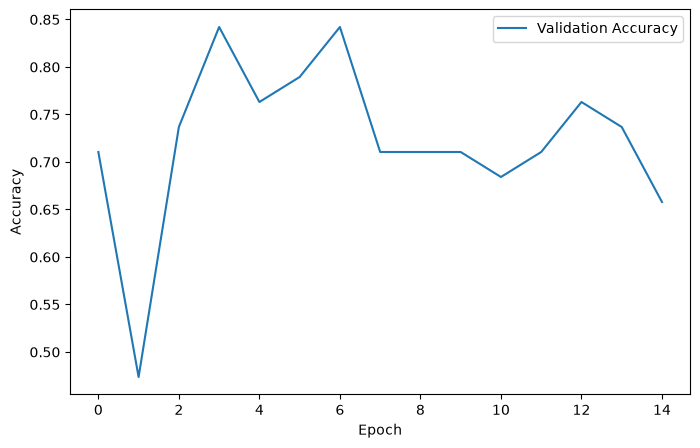

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


### 17. Load the Best Saved Checkpoint

The checkpoint with the lowest validation loss is restored before final test evaluation.


In [17]:
checkpoint = torch.load(
    MODEL_DIR / "best_multimodal_classifier.pth",
    map_location=device
)

image_encoder.load_state_dict(checkpoint["image_encoder"])
fusion_model.load_state_dict(checkpoint["fusion_model"])
classifier.load_state_dict(checkpoint["classifier"])


<All keys matched successfully>

### 18. Evaluate on the Held-Out Test Set

The final model produces a malignancy probability for each test case.


In [34]:
image_encoder.eval()
fusion_model.eval()
classifier.eval()

all_targets = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for batch in test_loader:
        images, input_ids, attention_mask, token_type_ids, targets = prepare_batch(batch)

        logits = forward_multimodal(
            images,
            input_ids,
            attention_mask,
            token_type_ids
        )

        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= 0.5).float()

        all_targets.extend(targets.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())


### 19. Calculate the Classification Metrics

The final test evaluation reports:

- accuracy
- precision
- recall
- F1-score
- ROC-AUC
- per-class classification results
- confusion matrix.


In [35]:
accuracy = accuracy_score(all_targets, all_predictions)
precision = precision_score(all_targets, all_predictions)
recall = recall_score(all_targets, all_predictions)
f1 = f1_score(all_targets, all_predictions)
auc = roc_auc_score(all_targets, all_probabilities)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")

print()
print(
    classification_report(
        all_targets,
        all_predictions,
        target_names=["Benign", "Malignant"]
    )
)


Accuracy:  0.7895
Precision: 0.8182
Recall:    0.6000
F1-score:  0.6923
ROC-AUC:   0.7913

              precision    recall  f1-score   support

      Benign       0.78      0.91      0.84        23
   Malignant       0.82      0.60      0.69        15

    accuracy                           0.79        38
   macro avg       0.80      0.76      0.77        38
weighted avg       0.79      0.79      0.78        38



### 20. Confusion Matrix


In [36]:
cm = confusion_matrix(all_targets, all_predictions)
print(cm)


[[21  2]
 [ 6  9]]
